# SVM (Support Vector Machine)

## ¿Cuál es el objetivo de SVM?

Las **Máquinas de Vectores de Soporte (SVM)** son un algoritmo de **clasificación** cuyo objetivo es encontrar el **hiperplano** que mejor separa dos clases, maximizando el **margen** entre ellas.

¿Qué significa esto? Dados datos de dos clases, existen infinitos hiperplanos que podrían separarlos. SVM elige el que tiene la **mayor distancia** a los puntos más cercanos de cada clase. Estos puntos más cercanos se llaman **vectores de soporte** (de ahí el nombre).

El hiperplano de decisión se define como:

$$
\mathbf{w} \cdot \mathbf{x} - b = 0
$$

Y la regla de clasificación es:

$$
\hat{y} = \text{sign}(\mathbf{w} \cdot \mathbf{x} - b) = \begin{cases} +1 & \text{si } \mathbf{w} \cdot \mathbf{x} - b > 0 \\ -1 & \text{si } \mathbf{w} \cdot \mathbf{x} - b < 0 \end{cases}
$$

Donde:

- $\mathbf{w}$: vector normal al hiperplano (define su orientación).
- $b$: sesgo (bias), desplaza el hiperplano respecto al origen.
- **Margen**: distancia entre los dos hiperplanos paralelos que pasan por los vectores de soporte.

**¿Por qué maximizar el margen?** Un margen más amplio significa mayor robustez: el clasificador generaliza mejor a datos nuevos porque hay más "espacio de seguridad" entre las clases.

**Nota:** En SVM las clases se codifican como $\{-1, +1\}$ (no $\{0, 1\}$ como en Regresión Logística).

**Supongamos un conjunto de datos simples**

Datos en 2D con dos clases linealmente separables:

| $x_1$ | $x_2$ | Clase ($y$) |
|-------|-------|------|
| 1     | 3     | -1   |
| 2     | 3     | -1   |
| 1     | 2     | -1   |
| 3     | 1     | -1   |
| 5     | 5     | +1   |
| 6     | 5     | +1   |
| 6     | 6     | +1   |
| 7     | 5     | +1   |

Hay muchas líneas que podrían separar estas dos clases. SVM encuentra la línea con el **margen más amplio**.

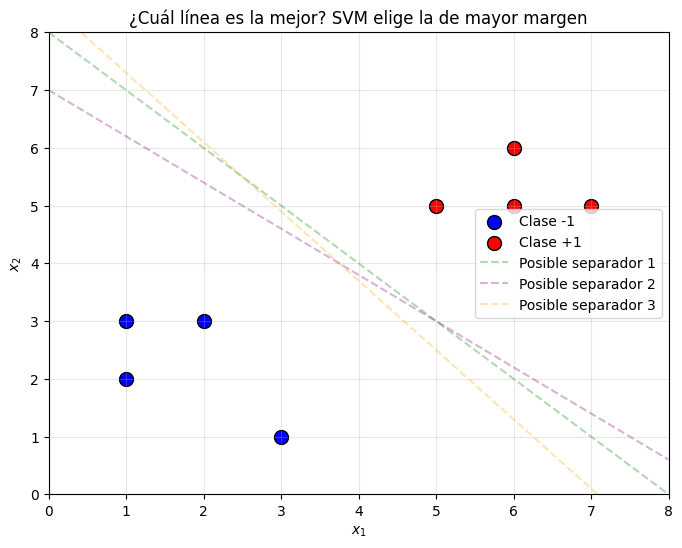

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

# Datos de ejemplo
X = np.array([[1, 3], [2, 3], [1, 2], [3, 1],
              [5, 5], [6, 5], [6, 6], [7, 5]])
y = np.array([-1, -1, -1, -1, 1, 1, 1, 1])

plt.figure(figsize=(8, 6))
plt.scatter(X[y == -1, 0], X[y == -1, 1], color='blue', s=100, label='Clase -1', edgecolors='black')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='red', s=100, label='Clase +1', edgecolors='black')

# Dibujar varias líneas posibles (para ilustrar que hay muchas)
x_line = np.linspace(0, 8, 100)
plt.plot(x_line, -x_line + 8, 'g--', alpha=0.3, label='Posible separador 1')
plt.plot(x_line, -0.8*x_line + 7, 'purple', alpha=0.3, linestyle='--', label='Posible separador 2')
plt.plot(x_line, -1.2*x_line + 8.5, 'orange', alpha=0.3, linestyle='--', label='Posible separador 3')

plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('¿Cuál línea es la mejor? SVM elige la de mayor margen')
plt.xlim(0, 8)
plt.ylim(0, 8)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## ¿Cómo encuentra SVM el hiperplano óptimo?

SVM plantea el problema como una **optimización**: encontrar $\mathbf{w}$ y $b$ tales que el **margen sea máximo** y todos los puntos estén **correctamente clasificados**.

Los puntos que están exactamente sobre el borde del margen son los **vectores de soporte**. Son los puntos más "difíciles" de clasificar y los únicos que importan para definir el hiperplano. Si removeremos cualquier otro punto, el hiperplano no cambiaría.

## Demostración Matemática

### Paso 1: El margen y las restricciones

El hiperplano de decisión es $\mathbf{w} \cdot \mathbf{x} - b = 0$. Definimos dos hiperplanos paralelos que pasan por los vectores de soporte:

$$
\mathbf{w} \cdot \mathbf{x} - b = +1 \quad \text{(hiperplano positivo)}
$$
$$
\mathbf{w} \cdot \mathbf{x} - b = -1 \quad \text{(hiperplano negativo)}
$$

La **distancia** entre estos dos hiperplanos (el margen) es:

$$
\text{margen} = \frac{2}{\|\mathbf{w}\|}
$$

**Derivación de la fórmula del margen:**

La distancia de un punto $\mathbf{x}_0$ a un hiperplano $\mathbf{w} \cdot \mathbf{x} - b = 0$ es $\frac{|\mathbf{w} \cdot \mathbf{x}_0 - b|}{\|\mathbf{w}\|}$.

Para un vector de soporte positivo ($\mathbf{w} \cdot \mathbf{x} - b = +1$), su distancia al hiperplano de decisión es $\frac{1}{\|\mathbf{w}\|}$. Para un vector de soporte negativo ($\mathbf{w} \cdot \mathbf{x} - b = -1$), también es $\frac{1}{\|\mathbf{w}\|}$. La distancia total (margen) es $\frac{2}{\|\mathbf{w}\|}$.

Las **restricciones** para clasificación correcta son:

$$
y_i(\mathbf{w} \cdot \mathbf{x}_i - b) \geq 1 \quad \forall i
$$

Esto garantiza que:
- Si $y_i = +1$: $\mathbf{w} \cdot \mathbf{x}_i - b \geq +1$ (el punto está del lado positivo).
- Si $y_i = -1$: $\mathbf{w} \cdot \mathbf{x}_i - b \leq -1$ (el punto está del lado negativo).

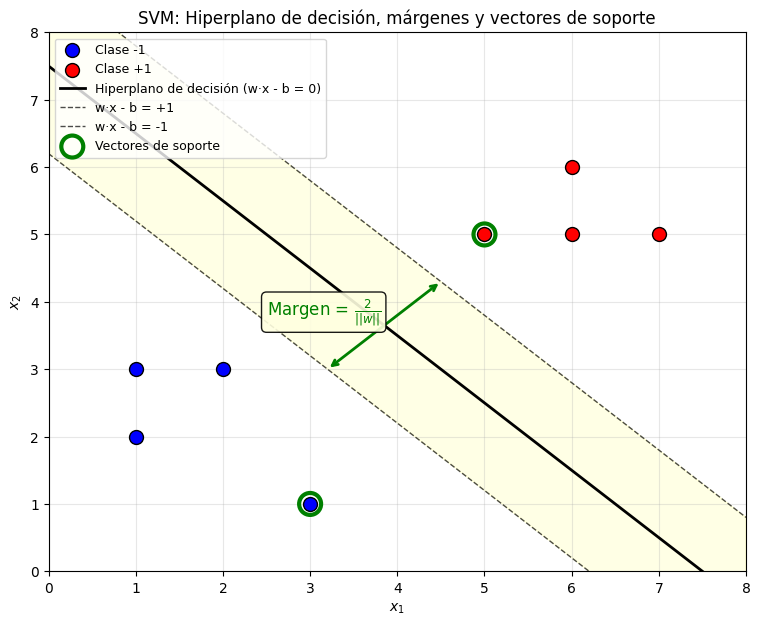

In [2]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(9, 7))

X = np.array([[1, 3], [2, 3], [1, 2], [3, 1],
              [5, 5], [6, 5], [6, 6], [7, 5]])
y = np.array([-1, -1, -1, -1, 1, 1, 1, 1])

ax.scatter(X[y == -1, 0], X[y == -1, 1], color='blue', s=100, edgecolors='black', zorder=5, label='Clase -1')
ax.scatter(X[y == 1, 0], X[y == 1, 1], color='red', s=100, edgecolors='black', zorder=5, label='Clase +1')

# Hiperplano de decisión y márgenes (aproximados para visualización)
x_line = np.linspace(0, 8, 100)
# Línea de decisión: w·x - b = 0
ax.plot(x_line, -x_line + 7.5, 'k-', linewidth=2, label='Hiperplano de decisión (w·x - b = 0)')
# Márgenes: w·x - b = ±1
ax.plot(x_line, -x_line + 8.8, 'k--', linewidth=1, alpha=0.7, label='w·x - b = +1')
ax.plot(x_line, -x_line + 6.2, 'k--', linewidth=1, alpha=0.7, label='w·x - b = -1')

# Sombrear margen
ax.fill_between(x_line, -x_line + 6.2, -x_line + 8.8, alpha=0.1, color='yellow')

# Marcar vectores de soporte (puntos más cercanos al hiperplano)
ax.scatter([3, 5], [1, 5], s=250, facecolors='none', edgecolors='green', linewidths=3,
           label='Vectores de soporte', zorder=6)

# Flecha del margen
ax.annotate('', xy=(4.5, 4.3), xytext=(3.2, 3.0),
            arrowprops=dict(arrowstyle='<->', color='green', lw=2))
ax.annotate('Margen = $\\frac{2}{||w||}$', xy=(2.5, 3.8), fontsize=12, color='green',
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_title('SVM: Hiperplano de decisión, márgenes y vectores de soporte')
ax.set_xlim(0, 8)
ax.set_ylim(0, 8)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left', fontsize=9)
plt.show()

### Paso 2: El problema de optimización

Queremos **maximizar el margen** $\frac{2}{\|\mathbf{w}\|}$ sujeto a que todos los puntos estén bien clasificados. Maximizar $\frac{2}{\|\mathbf{w}\|}$ es equivalente a **minimizar** $\frac{1}{2}\|\mathbf{w}\|^2$.

El problema de optimización original (**hard-margin SVM**) es:

$$
\min_{\mathbf{w}, b} \frac{1}{2} \|\mathbf{w}\|^2 \quad \text{sujeto a} \quad y_i(\mathbf{w} \cdot \mathbf{x}_i - b) \geq 1 \quad \forall i
$$

En la práctica, los datos rara vez son perfectamente separables. La versión **soft-margin** permite errores de clasificación, penalizándolos con un parámetro $\lambda$ (regularización).

La función de costo se convierte en la **Hinge Loss** más un término de regularización:

$$
J(\mathbf{w}, b) = \lambda \|\mathbf{w}\|^2 + \frac{1}{n}\sum_{i=1}^{n} \max(0, \ 1 - y_i(\mathbf{w} \cdot \mathbf{x}_i - b))
$$

Donde:

- $\lambda \|\mathbf{w}\|^2$: **regularización** (controla el tamaño del margen).
- $\max(0, 1 - y_i(\mathbf{w} \cdot \mathbf{x}_i - b))$: **hinge loss** (penaliza puntos mal clasificados o dentro del margen).

### Paso 3: La Hinge Loss

La **hinge loss** para un solo punto es:

$$
\ell_i = \max(0, \ 1 - y_i(\mathbf{w} \cdot \mathbf{x}_i - b))
$$

Su comportamiento:

- Si $y_i(\mathbf{w} \cdot \mathbf{x}_i - b) \geq 1$: el punto está **correctamente clasificado y fuera del margen** → $\ell_i = 0$ (sin penalización).
- Si $0 < y_i(\mathbf{w} \cdot \mathbf{x}_i - b) < 1$: el punto está **correctamente clasificado pero dentro del margen** → $\ell_i > 0$ (penalización proporcional).
- Si $y_i(\mathbf{w} \cdot \mathbf{x}_i - b) < 0$: el punto está **mal clasificado** → $\ell_i > 1$ (penalización alta).

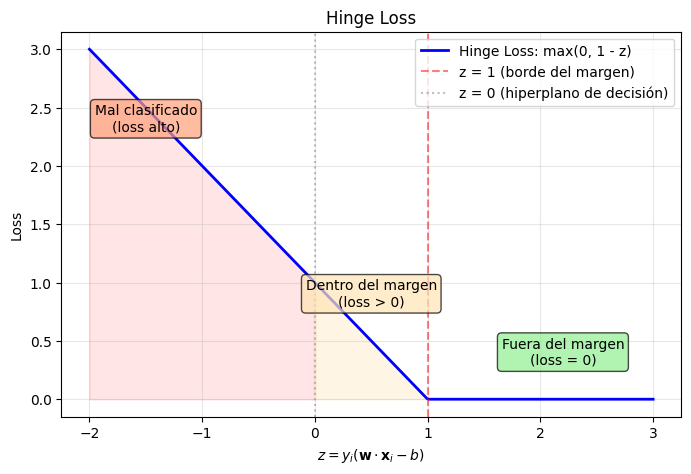

In [3]:
import matplotlib.pyplot as plt
import numpy as np

z = np.linspace(-2, 3, 300)
hinge = np.maximum(0, 1 - z)

plt.figure(figsize=(8, 5))
plt.plot(z, hinge, 'b-', linewidth=2, label='Hinge Loss: max(0, 1 - z)')
plt.axvline(x=1, color='red', linestyle='--', alpha=0.5, label='z = 1 (borde del margen)')
plt.axvline(x=0, color='gray', linestyle=':', alpha=0.5, label='z = 0 (hiperplano de decisión)')

# Regiones
plt.fill_between(z, 0, hinge, where=(z < 0), alpha=0.1, color='red')
plt.fill_between(z, 0, hinge, where=((z >= 0) & (z < 1)), alpha=0.1, color='orange')

plt.annotate('Mal clasificado\n(loss alto)', xy=(-1.5, 2.3), fontsize=10, ha='center',
             bbox=dict(boxstyle='round', facecolor='lightsalmon', alpha=0.7))
plt.annotate('Dentro del margen\n(loss > 0)', xy=(0.5, 0.8), fontsize=10, ha='center',
             bbox=dict(boxstyle='round', facecolor='moccasin', alpha=0.7))
plt.annotate('Fuera del margen\n(loss = 0)', xy=(2.2, 0.3), fontsize=10, ha='center',
             bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))

plt.xlabel('$z = y_i(\mathbf{w} \cdot \mathbf{x}_i - b)$')
plt.ylabel('Loss')
plt.title('Hinge Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Paso 4: Gradientes para descenso de gradiente

Para minimizar la función de costo con **descenso de gradiente**, necesitamos los gradientes. Los calculamos por casos, según si el punto satisface o no la condición del margen.

**Caso 1: $y_i(\mathbf{w} \cdot \mathbf{x}_i - b) \geq 1$** (correctamente clasificado, fuera del margen)

La hinge loss es 0, así que solo queda el término de regularización:

$$
\frac{\partial J}{\partial \mathbf{w}} = 2\lambda \mathbf{w}
$$
$$
\frac{\partial J}{\partial b} = 0
$$

**Caso 2: $y_i(\mathbf{w} \cdot \mathbf{x}_i - b) < 1$** (dentro del margen o mal clasificado)

Tanto la regularización como la hinge loss contribuyen:

$$
\frac{\partial J}{\partial \mathbf{w}} = 2\lambda \mathbf{w} - y_i \mathbf{x}_i
$$
$$
\frac{\partial J}{\partial b} = y_i
$$

La **regla de actualización** en cada iteración es:

$$
\mathbf{w} \leftarrow \mathbf{w} - \alpha \cdot \frac{\partial J}{\partial \mathbf{w}}
$$
$$
b \leftarrow b - \alpha \cdot \frac{\partial J}{\partial b}
$$

Donde $\alpha$ es el learning rate.

### El parámetro de regularización $\lambda$

El parámetro $\lambda$ controla el balance entre:

- **Margen amplio** ($\lambda$ grande): margen más ancho, pero posiblemente más errores de clasificación.
- **Pocos errores** ($\lambda$ pequeño): clasifica mejor los datos de entrenamiento, pero con margen más estrecho (riesgo de sobreajuste).

En la práctica, se prueba con validación cruzada para encontrar el valor óptimo.

### Resumen del algoritmo

**Entrenamiento:**

1. Convertir etiquetas a $\{-1, +1\}$.
2. Inicializar $\mathbf{w} = \mathbf{0}$, $b = 0$.
3. Para cada iteración y cada punto $(\mathbf{x}_i, y_i)$:
   - Si $y_i(\mathbf{w} \cdot \mathbf{x}_i - b) \geq 1$:
     - $\mathbf{w} \leftarrow \mathbf{w} - \alpha \cdot 2\lambda\mathbf{w}$
   - Si no:
     - $\mathbf{w} \leftarrow \mathbf{w} - \alpha(2\lambda\mathbf{w} - y_i\mathbf{x}_i)$
     - $b \leftarrow b - \alpha \cdot y_i$

**Predicción:**

$$
\hat{y} = \text{sign}(\mathbf{w} \cdot \mathbf{x} - b)
$$

### Ejemplo numérico

Usemos un ejemplo simplificado con **2 features** y **4 muestras**.

| $x_1$ | $x_2$ | $y$ |
|-------|-------|-----|
| 1     | 2     | -1  |
| 2     | 1     | -1  |
| 4     | 5     | +1  |
| 5     | 4     | +1  |

Inicializamos: $\mathbf{w} = (0, 0)$, $b = 0$, $\alpha = 0.01$, $\lambda = 0.01$

**Iteración 1, punto 1:** $\mathbf{x}_1 = (1, 2)$, $y_1 = -1$

$$
y_1(\mathbf{w} \cdot \mathbf{x}_1 - b) = -1 \cdot (0 \cdot 1 + 0 \cdot 2 - 0) = 0
$$

Como $0 < 1$, estamos en el **Caso 2** (dentro del margen):

$$
\mathbf{w} \leftarrow (0, 0) - 0.01 \cdot (2 \cdot 0.01 \cdot (0, 0) - (-1) \cdot (1, 2)) = (0, 0) - 0.01 \cdot (1, 2) = (-0.01, -0.02)
$$

$$
b \leftarrow 0 - 0.01 \cdot (-1) = 0.01
$$

Después de una sola muestra, $\mathbf{w}$ ya apunta hacia el lado negativo (componentes negativas porque $y = -1$), lo cual es el comportamiento correcto. El proceso se repite miles de veces hasta que los pesos convergen.

In [4]:
import numpy as np

# Datos de ejemplo
X_ej = np.array([[1, 2], [2, 1], [4, 5], [5, 4]], dtype=np.float64)
y_ej = np.array([-1, -1, 1, 1])

w = np.zeros(2)
b = 0.0
lr = 0.01
lam = 0.01

print("=== Ejemplo numérico: SVM paso a paso ===")
print(f"Datos: X = {X_ej.tolist()}, y = {y_ej.tolist()}")
print(f"Parámetros iniciales: w = {w}, b = {b}, lr = {lr}, λ = {lam}\n")

for it in range(3):
    print(f"--- Iteración {it + 1} ---")
    for idx, (x_i, y_i) in enumerate(zip(X_ej, y_ej)):
        condition_val = y_i * (np.dot(x_i, w) - b)
        condition = condition_val >= 1

        if condition:
            dw = 2 * lam * w
            db = 0
            caso = "Caso 1 (fuera del margen)"
        else:
            dw = 2 * lam * w - y_i * x_i
            db = y_i
            caso = "Caso 2 (dentro del margen)"

        w = w - lr * dw
        b = b - lr * db

        print(f"  x={x_i}, y={y_i:+d}: y(w·x-b)={condition_val:+.4f} → {caso}")
        print(f"    w = ({w[0]:.4f}, {w[1]:.4f}), b = {b:.4f}")
    print()

=== Ejemplo numérico: SVM paso a paso ===
Datos: X = [[1.0, 2.0], [2.0, 1.0], [4.0, 5.0], [5.0, 4.0]], y = [-1, -1, 1, 1]
Parámetros iniciales: w = [0. 0.], b = 0.0, lr = 0.01, λ = 0.01

--- Iteración 1 ---
  x=[1. 2.], y=-1: y(w·x-b)=-0.0000 → Caso 2 (dentro del margen)
    w = (-0.0100, -0.0200), b = 0.0100
  x=[2. 1.], y=-1: y(w·x-b)=+0.0500 → Caso 2 (dentro del margen)
    w = (-0.0300, -0.0300), b = 0.0200
  x=[4. 5.], y=+1: y(w·x-b)=-0.2900 → Caso 2 (dentro del margen)
    w = (0.0100, 0.0200), b = 0.0100
  x=[5. 4.], y=+1: y(w·x-b)=+0.1201 → Caso 2 (dentro del margen)
    w = (0.0600, 0.0600), b = 0.0000

--- Iteración 2 ---
  x=[1. 2.], y=-1: y(w·x-b)=-0.1800 → Caso 2 (dentro del margen)
    w = (0.0500, 0.0400), b = 0.0100
  x=[2. 1.], y=-1: y(w·x-b)=-0.1300 → Caso 2 (dentro del margen)
    w = (0.0300, 0.0300), b = 0.0200
  x=[4. 5.], y=+1: y(w·x-b)=+0.2499 → Caso 2 (dentro del margen)
    w = (0.0700, 0.0800), b = 0.0100
  x=[5. 4.], y=+1: y(w·x-b)=+0.6598 → Caso 2 (dentro d

## Implementación con Código

### Funciones

In [5]:
import numpy as np

def svm_fit(X, y, learning_rate=0.001, lambda_param=0.01, n_iters=1000):
    """Entrena un SVM lineal con descenso de gradiente"""
    n_samples, n_features = X.shape
    y_ = np.where(y <= 0, -1, 1)

    w = np.zeros(n_features)
    b = 0

    for _ in range(n_iters):
        for idx, x_i in enumerate(X):
            condition = y_[idx] * (np.dot(x_i, w) - b) >= 1
            if condition:
                w -= learning_rate * (2 * lambda_param * w)
            else:
                w -= learning_rate * (2 * lambda_param * w - np.dot(x_i, y_[idx]))
                b -= learning_rate * y_[idx]

    return w, b

def svm_predict(X, w, b):
    """Predice clases (-1 o +1)"""
    approx = np.dot(X, w) - b
    return np.sign(approx)

w = [0.58977016 0.17946483]
b = -0.1520000000000001
Accuracy: 1.0000


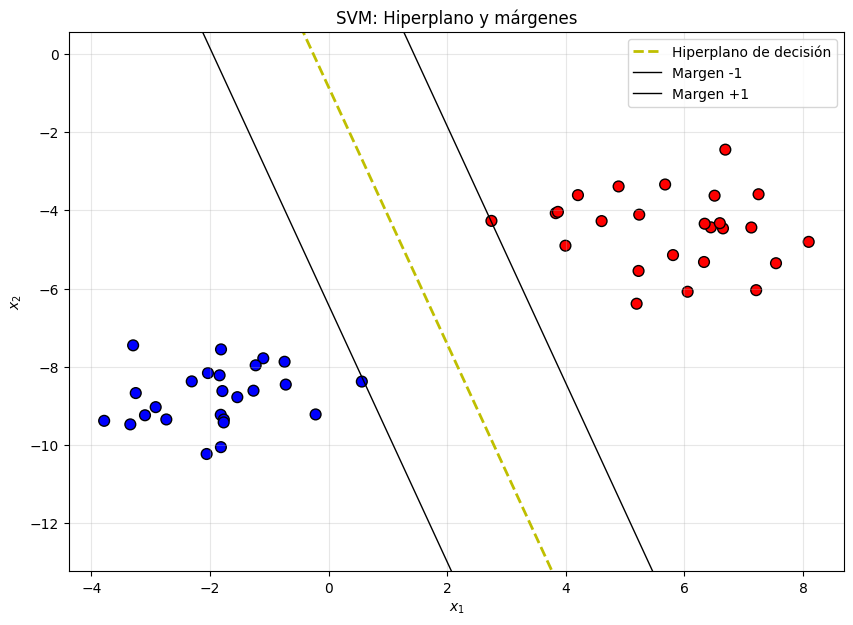

In [6]:
import matplotlib.pyplot as plt
from sklearn import datasets

# Generar datos
X, y = datasets.make_blobs(
    n_samples=50, n_features=2, centers=2, cluster_std=1.05, random_state=40
)
y = np.where(y == 0, -1, 1)

# Entrenar
w, b = svm_fit(X, y)
print(f"w = {w}")
print(f"b = {b}")

# Predecir y evaluar
predictions = svm_predict(X, w, b)
accuracy = np.sum(y == predictions) / len(y)
print(f"Accuracy: {accuracy:.4f}")

# Visualizar
def get_hyperplane_value(x, w, b, offset):
    return (-w[0] * x + b + offset) / w[1]

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(X[:, 0], X[:, 1], marker='o', c=y, cmap='bwr', s=60, edgecolors='black')

x0_1 = np.amin(X[:, 0])
x0_2 = np.amax(X[:, 0])

# Hiperplano de decisión
ax.plot([x0_1, x0_2], [get_hyperplane_value(x0_1, w, b, 0), get_hyperplane_value(x0_2, w, b, 0)],
        'y--', linewidth=2, label='Hiperplano de decisión')
# Márgenes
ax.plot([x0_1, x0_2], [get_hyperplane_value(x0_1, w, b, -1), get_hyperplane_value(x0_2, w, b, -1)],
        'k-', linewidth=1, label='Margen -1')
ax.plot([x0_1, x0_2], [get_hyperplane_value(x0_1, w, b, 1), get_hyperplane_value(x0_2, w, b, 1)],
        'k-', linewidth=1, label='Margen +1')

ax.set_ylim([np.amin(X[:, 1]) - 3, np.amax(X[:, 1]) + 3])
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_title('SVM: Hiperplano y márgenes')
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

### Clase

#### Lineal

In [7]:
import numpy as np
import matplotlib.pyplot as plt


class SVM:
    def __init__(self, learning_rate=0.001, lambda_param=0.01, n_iters=1000):
        self.lr = learning_rate
        self.lambda_param = lambda_param
        self.n_iters = n_iters
        self.w = None
        self.b = None
        self.losses = []

    def fit(self, X, y):
        """Entrena el SVM con descenso de gradiente"""
        n_samples, n_features = X.shape
        y_ = np.where(y <= 0, -1, 1)

        self.w = np.zeros(n_features)
        self.b = 0
        self.losses = []

        for _ in range(self.n_iters):
            for idx, x_i in enumerate(X):
                condition = y_[idx] * (np.dot(x_i, self.w) - self.b) >= 1
                if condition:
                    self.w -= self.lr * (2 * self.lambda_param * self.w)
                else:
                    self.w -= self.lr * (
                        2 * self.lambda_param * self.w - np.dot(x_i, y_[idx])
                    )
                    self.b -= self.lr * y_[idx]

            # Registrar loss
            loss = self._compute_loss(X, y_)
            self.losses.append(loss)

    def predict(self, X):
        """Predice clases (-1 o +1)"""
        approx = np.dot(X, self.w) - self.b
        return np.sign(approx)

    def score(self, X, y):
        """Calcula la accuracy del modelo"""
        y_ = np.where(y <= 0, -1, 1)
        predictions = self.predict(X)
        return np.sum(predictions == y_) / len(y_)

    def _compute_loss(self, X, y):
        """Calcula la hinge loss + regularización"""
        distances = 1 - y * (np.dot(X, self.w) - self.b)
        hinge_loss = np.mean(np.maximum(0, distances))
        return self.lambda_param * np.dot(self.w, self.w) + hinge_loss

    def plot_loss(self):
        """Grafica la evolución del loss durante el entrenamiento"""
        plt.figure(figsize=(8, 5))
        plt.plot(self.losses, 'b-', linewidth=1)
        plt.xlabel('Iteración')
        plt.ylabel('Loss (Hinge + Regularización)')
        plt.title('Evolución del Loss durante el entrenamiento')
        plt.grid(True, alpha=0.3)
        plt.show()

    def plot_decision_boundary(self, X, y):
        """Visualiza el hiperplano, márgenes y vectores de soporte"""
        y_ = np.where(y <= 0, -1, 1)

        def get_hyperplane_value(x, w, b, offset):
            return (-w[0] * x + b + offset) / w[1]

        fig, ax = plt.subplots(figsize=(10, 7))
        ax.scatter(X[:, 0], X[:, 1], marker='o', c=y_, cmap='bwr', s=60, edgecolors='black')

        x0_1 = np.amin(X[:, 0])
        x0_2 = np.amax(X[:, 0])

        # Hiperplano de decisión
        ax.plot([x0_1, x0_2],
                [get_hyperplane_value(x0_1, self.w, self.b, 0),
                 get_hyperplane_value(x0_2, self.w, self.b, 0)],
                'y--', linewidth=2, label='Hiperplano de decisión')

        # Márgenes
        ax.plot([x0_1, x0_2],
                [get_hyperplane_value(x0_1, self.w, self.b, -1),
                 get_hyperplane_value(x0_2, self.w, self.b, -1)],
                'k-', linewidth=1, label='Margen -1')
        ax.plot([x0_1, x0_2],
                [get_hyperplane_value(x0_1, self.w, self.b, 1),
                 get_hyperplane_value(x0_2, self.w, self.b, 1)],
                'k-', linewidth=1, label='Margen +1')

        # Sombrear margen
        x_fill = np.linspace(x0_1, x0_2, 100)
        y_m = [get_hyperplane_value(x, self.w, self.b, -1) for x in x_fill]
        y_p = [get_hyperplane_value(x, self.w, self.b, 1) for x in x_fill]
        ax.fill_between(x_fill, y_m, y_p, alpha=0.1, color='yellow')

        # Marcar vectores de soporte (puntos cerca del margen)
        distances = y_ * (np.dot(X, self.w) - self.b)
        sv_mask = (distances >= 0.9) & (distances <= 1.1)
        if sv_mask.any():
            ax.scatter(X[sv_mask, 0], X[sv_mask, 1], s=200, facecolors='none',
                       edgecolors='green', linewidths=2, label='Vectores de soporte')

        ax.set_ylim([np.amin(X[:, 1]) - 3, np.amax(X[:, 1]) + 3])
        ax.set_xlabel('$x_1$')
        ax.set_ylabel('$x_2$')
        ax.set_title('SVM: Hiperplano, márgenes y vectores de soporte')
        ax.grid(True, alpha=0.3)
        ax.legend()
        plt.show()

w = [0.58977016 0.17946483]
b = -0.1520
Accuracy: 1.0000


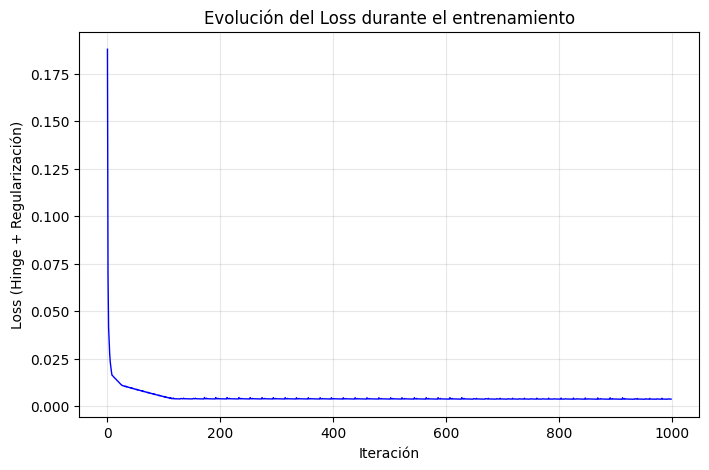

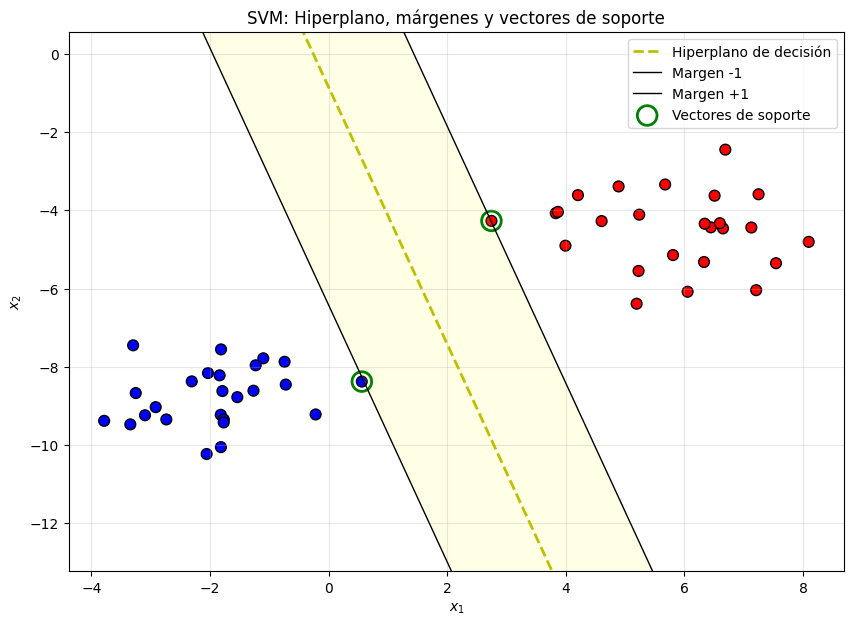

In [8]:
from sklearn import datasets

# Generar datos
X, y = datasets.make_blobs(
    n_samples=50, n_features=2, centers=2, cluster_std=1.05, random_state=40
)
y = np.where(y == 0, -1, 1)

# Crear y entrenar modelo
model = SVM(learning_rate=0.001, lambda_param=0.01, n_iters=1000)
model.fit(X, y)

# Evaluar
acc = model.score(X, y)
print(f"w = {model.w}")
print(f"b = {model.b:.4f}")
print(f"Accuracy: {acc:.4f}")

# Visualizar loss y frontera
model.plot_loss()
model.plot_decision_boundary(X, y)

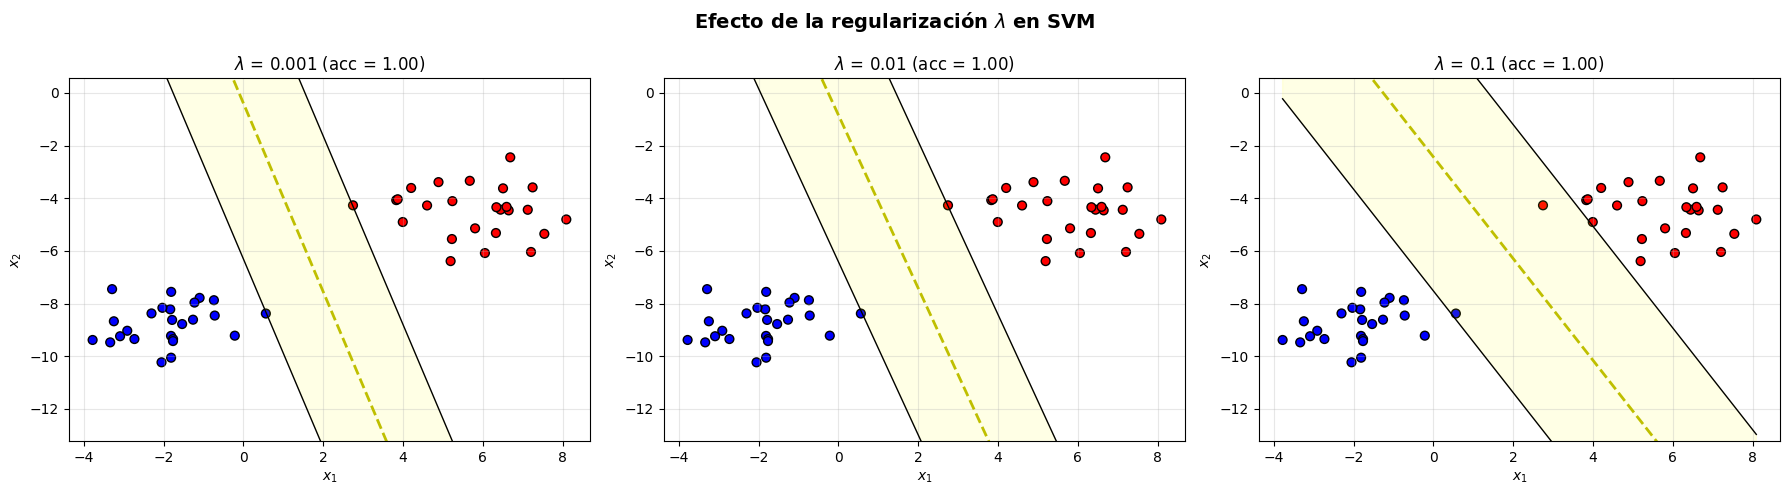

In [9]:
# Comparar diferentes valores de λ (regularización)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

lambdas = [0.001, 0.01, 0.1]
for ax, lam in zip(axes, lambdas):
    model_comp = SVM(learning_rate=0.001, lambda_param=lam, n_iters=1000)
    model_comp.fit(X, y)
    acc = model_comp.score(X, y)

    def get_hp(x, w, b, off):
        return (-w[0] * x + b + off) / w[1]

    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', s=40, edgecolors='black')

    x0_1, x0_2 = np.amin(X[:, 0]), np.amax(X[:, 0])
    ax.plot([x0_1, x0_2], [get_hp(x0_1, model_comp.w, model_comp.b, 0),
                            get_hp(x0_2, model_comp.w, model_comp.b, 0)], 'y--', linewidth=2)
    ax.plot([x0_1, x0_2], [get_hp(x0_1, model_comp.w, model_comp.b, -1),
                            get_hp(x0_2, model_comp.w, model_comp.b, -1)], 'k-', linewidth=1)
    ax.plot([x0_1, x0_2], [get_hp(x0_1, model_comp.w, model_comp.b, 1),
                            get_hp(x0_2, model_comp.w, model_comp.b, 1)], 'k-', linewidth=1)

    x_fill = np.linspace(x0_1, x0_2, 100)
    ax.fill_between(x_fill,
                    [get_hp(x, model_comp.w, model_comp.b, -1) for x in x_fill],
                    [get_hp(x, model_comp.w, model_comp.b, 1) for x in x_fill],
                    alpha=0.1, color='yellow')

    ax.set_ylim([np.amin(X[:, 1]) - 3, np.amax(X[:, 1]) + 3])
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(f'$\lambda$ = {lam} (acc = {acc:.2f})')
    ax.grid(True, alpha=0.3)

plt.suptitle('Efecto de la regularización $\lambda$ en SVM', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### No lineal

In [10]:
import numpy as np
import matplotlib.pyplot as plt


class KernelSVM:
    """
    SVM no lineal (kernelizado) entrenado en el dual con SMO (simplificado).

    - Soporta kernels: 'rbf', 'poly', 'linear'
    - Optimiza:
        max_a  sum_i a_i - 1/2 sum_{i,j} a_i a_j y_i y_j K(x_i, x_j)
      s.t.   0 <= a_i <= C,  sum_i a_i y_i = 0
    """

    def __init__(
        self,
        C=1.0,
        kernel="rbf",
        gamma=None,      # para RBF: exp(-gamma ||x-z||^2). Si None, usa 1/n_features
        degree=3,        # para Poly
        coef0=1.0,       # para Poly
        tol=1e-3,
        max_passes=10,
        max_iters=100000,
        seed=42,
    ):
        self.C = float(C)
        self.kernel = kernel
        self.gamma = gamma
        self.degree = int(degree)
        self.coef0 = float(coef0)
        self.tol = float(tol)
        self.max_passes = int(max_passes)
        self.max_iters = int(max_iters)
        self.rng = np.random.default_rng(seed)

        # Aprendidos
        self.X = None
        self.y = None
        self.alphas = None
        self.b = 0.0
        self.K = None
        self.losses = []   # (opcional) - dual objective a lo largo del entrenamiento

        # Solo para kernel lineal (si se quiere recuperar w)
        self.w = None

    def _kernel_fn(self, X1, X2):
        if self.kernel == "linear":
            return X1 @ X2.T

        if self.kernel == "rbf":
            # K(x,z) = exp(-gamma ||x-z||^2)
            if self.gamma is None:
                gamma = 1.0 / X1.shape[1]
            else:
                gamma = self.gamma

            # ||x-z||^2 = ||x||^2 + ||z||^2 - 2 x·z
            X1_sq = np.sum(X1**2, axis=1).reshape(-1, 1)
            X2_sq = np.sum(X2**2, axis=1).reshape(1, -1)
            d2 = X1_sq + X2_sq - 2.0 * (X1 @ X2.T)
            return np.exp(-gamma * d2)

        if self.kernel == "poly":
            # K(x,z) = (gamma x·z + coef0)^degree
            if self.gamma is None:
                gamma = 1.0 / X1.shape[1]
            else:
                gamma = self.gamma
            return (gamma * (X1 @ X2.T) + self.coef0) ** self.degree

        raise ValueError(f"Kernel no soportado: {self.kernel}")

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel()
        y_ = np.where(y <= 0, -1.0, 1.0)

        n_samples, n_features = X.shape
        self.X = X
        self.y = y_
        self.alphas = np.zeros(n_samples, dtype=float)
        self.b = 0.0
        self.losses = []

        # Precomputar matriz kernel (para datasets medianos/pequeños)
        self.K = self._kernel_fn(self.X, self.X)

        passes = 0
        iters = 0

        while passes < self.max_passes and iters < self.max_iters:
            num_changed = 0

            for i in range(n_samples):
                # f(x_i) = sum_j a_j y_j K(x_j, x_i) + b
                f_i = np.sum(self.alphas * self.y * self.K[:, i]) + self.b
                E_i = f_i - self.y[i]

                # Condiciones KKT (con tolerancia)
                cond1 = (self.y[i] * f_i < 1 - self.tol) and (self.alphas[i] < self.C)
                cond2 = (self.y[i] * f_i > 1 + self.tol) and (self.alphas[i] > 0)

                if not (cond1 or cond2):
                    continue

                # Elegir j != i aleatoriamente
                j = i
                while j == i:
                    j = int(self.rng.integers(0, n_samples))

                f_j = np.sum(self.alphas * self.y * self.K[:, j]) + self.b
                E_j = f_j - self.y[j]

                alpha_i_old = self.alphas[i]
                alpha_j_old = self.alphas[j]

                # L, H (clipping)
                if self.y[i] != self.y[j]:
                    L = max(0.0, alpha_j_old - alpha_i_old)
                    H = min(self.C, self.C + alpha_j_old - alpha_i_old)
                else:
                    L = max(0.0, alpha_i_old + alpha_j_old - self.C)
                    H = min(self.C, alpha_i_old + alpha_j_old)

                if abs(H - L) < 1e-12:
                    continue

                # eta = 2K_ij - K_ii - K_jj  (nota: usualmente es negativo)
                K_ii = self.K[i, i]
                K_jj = self.K[j, j]
                K_ij = self.K[i, j]
                eta = 2.0 * K_ij - K_ii - K_jj
                if eta >= 0:
                    continue

                # Actualizar alpha_j
                self.alphas[j] = alpha_j_old - (self.y[j] * (E_i - E_j)) / eta

                # Clip a [L, H]
                if self.alphas[j] > H:
                    self.alphas[j] = H
                elif self.alphas[j] < L:
                    self.alphas[j] = L

                if abs(self.alphas[j] - alpha_j_old) < 1e-5:
                    self.alphas[j] = alpha_j_old
                    continue

                # Actualizar alpha_i (por restricción sum a_i y_i = 0)
                self.alphas[i] = alpha_i_old + self.y[i] * self.y[j] * (alpha_j_old - self.alphas[j])

                # Actualizar bias b (b1, b2)
                b_old = self.b
                b1 = b_old - E_i \
                     - self.y[i] * (self.alphas[i] - alpha_i_old) * K_ii \
                     - self.y[j] * (self.alphas[j] - alpha_j_old) * K_ij

                b2 = b_old - E_j \
                     - self.y[i] * (self.alphas[i] - alpha_i_old) * K_ij \
                     - self.y[j] * (self.alphas[j] - alpha_j_old) * K_jj

                if 0 < self.alphas[i] < self.C:
                    self.b = b1
                elif 0 < self.alphas[j] < self.C:
                    self.b = b2
                else:
                    self.b = 0.5 * (b1 + b2)

                num_changed += 1

            # Registrar una métrica tipo "loss" (dual objective, opcional)
            self.losses.append(self._dual_objective())

            if num_changed == 0:
                passes += 1
            else:
                passes = 0

            iters += 1

        # Si el kernel es lineal, podemos reconstruir w (solo informativo)
        if self.kernel == "linear":
            self.w = (self.alphas * self.y) @ self.X
        else:
            self.w = None

        return self

    def _dual_objective(self):
        # W(a) = sum a_i - 1/2 sum_{i,j} a_i a_j y_i y_j K_ij
        a = self.alphas
        y = self.y
        term1 = np.sum(a)
        # (a*y) is vector; objective uses (a_i y_i)(a_j y_j)K_ij
        ay = a * y
        term2 = 0.5 * np.sum((ay[:, None] * ay[None, :]) * self.K)
        return term1 - term2

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        Kx = self._kernel_fn(self.X, X)  # shape: (n_train, n_test)
        return (self.alphas * self.y) @ Kx + self.b

    def predict(self, X):
        return np.sign(self.decision_function(X))

    def score(self, X, y):
        y = np.asarray(y).ravel()
        y_ = np.where(y <= 0, -1.0, 1.0)
        preds = self.predict(X)
        return np.mean(preds == y_)

    # ---------------------------
    # Plots
    # ---------------------------
    def plot_loss(self):
        plt.figure(figsize=(8, 5))
        plt.plot(self.losses, linewidth=1)
        plt.xlabel("Iteración (pass SMO)")
        plt.ylabel("Objetivo dual (más alto es mejor)")
        plt.title("Evolución del objetivo dual durante el entrenamiento")
        plt.grid(True, alpha=0.3)
        plt.show()

    def plot_decision_boundary(self, X, y, grid_step=0.02, margin=False):
        """
        Para no lineal: se grafica el contorno de f(x)=0 (y opcionalmente f(x)=±1).
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel()
        y_ = np.where(y <= 0, -1.0, 1.0)

        x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
        y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0

        xx, yy = np.meshgrid(
            np.arange(x_min, x_max, grid_step),
            np.arange(y_min, y_max, grid_step),
        )
        grid = np.c_[xx.ravel(), yy.ravel()]
        Z = self.decision_function(grid).reshape(xx.shape)

        fig, ax = plt.subplots(figsize=(10, 7))
        ax.scatter(X[:, 0], X[:, 1], c=y_, cmap="bwr", s=60, edgecolors="black")

        # Frontera f(x)=0
        ax.contour(xx, yy, Z, levels=[0], linewidths=2)
        if margin:
            ax.contour(xx, yy, Z, levels=[-1, 1], linewidths=1, linestyles="--")

        # Vectores de soporte: alphas > 0 (con umbral)
        sv = self.alphas > 1e-6
        if np.any(sv):
            ax.scatter(
                self.X[sv, 0],
                self.X[sv, 1],
                s=200,
                facecolors="none",
                edgecolors="green",
                linewidths=2,
                label="Vectores de soporte",
            )

        ax.set_xlabel("$x_1$")
        ax.set_ylabel("$x_2$")
        ax.set_title(f"SVM no lineal (kernel={self.kernel})")
        ax.grid(True, alpha=0.3)
        ax.legend()
        plt.show()

Accuracy: 1.0


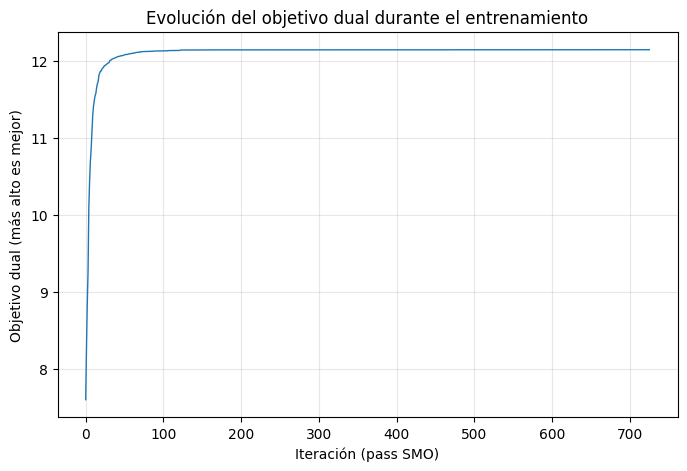

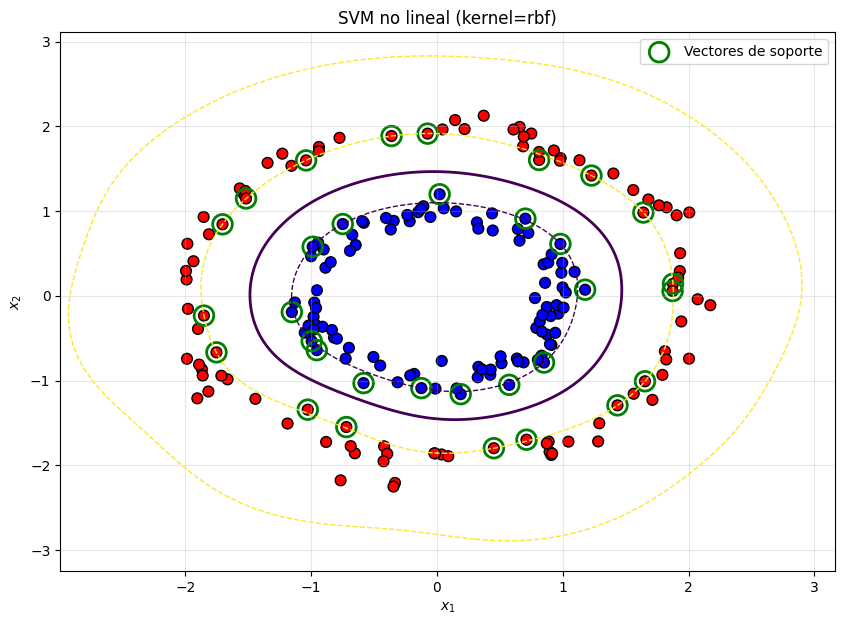

In [11]:
# Dataset no lineal simple (dos círculos)
rng = np.random.default_rng(0)
n = 200
r1 = 1.0 + 0.1 * rng.standard_normal(n // 2)
t1 = 2 * np.pi * rng.random(n // 2)
X1 = np.c_[r1 * np.cos(t1), r1 * np.sin(t1)]

r2 = 2.0 + 0.1 * rng.standard_normal(n // 2)
t2 = 2 * np.pi * rng.random(n // 2)
X2 = np.c_[r2 * np.cos(t2), r2 * np.sin(t2)]

X = np.vstack([X1, X2])
y = np.hstack([-np.ones(n // 2), np.ones(n // 2)])

model = KernelSVM(C=1.0, kernel="rbf", gamma=1.0, tol=1e-3, max_passes=10)
model.fit(X, y)

print("Accuracy:", model.score(X, y))

model.plot_loss()
model.plot_decision_boundary(X, y, margin=True)

=== Resultados en XOR (2D) ===
Accuracy SVM lineal (2D):    0.5400
Accuracy SVM kernel (no lin): 1.0000


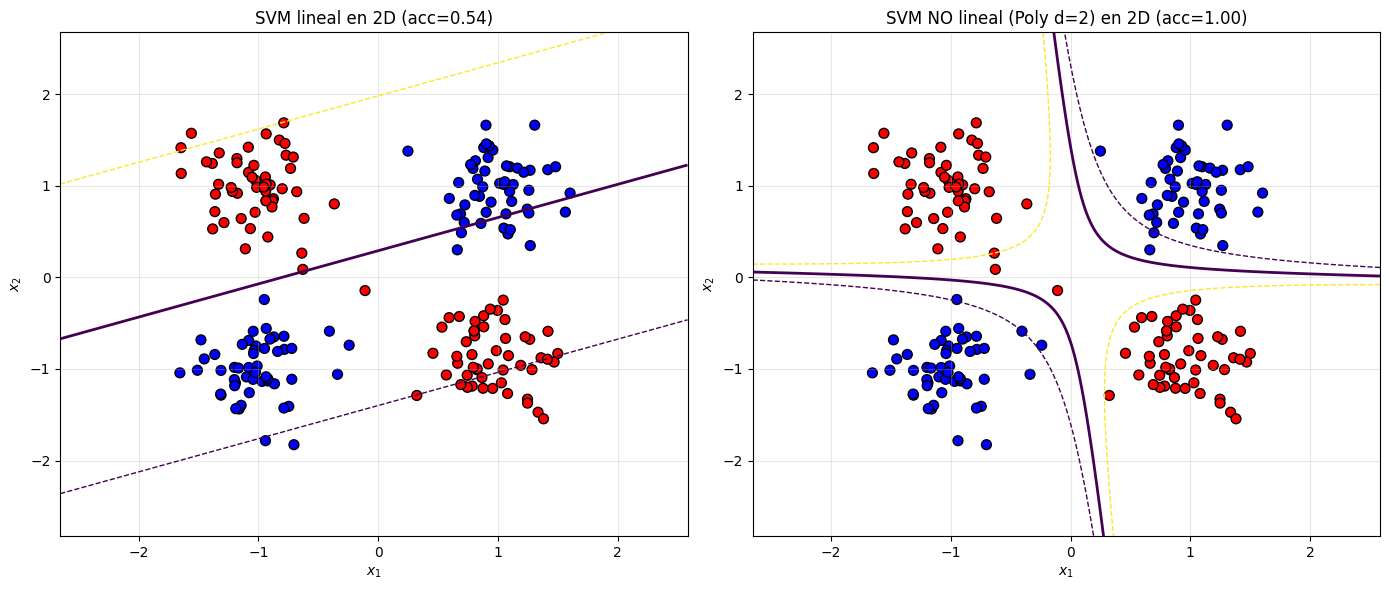

In [12]:
# Datos: XOR (NO separable linealmente en 2D)
#    Pero si mapeas a 3D con z = x1*x2, se vuelve separable

def make_xor(n_samples=200, noise=0.25, seed=40):
    rng = np.random.default_rng(seed)
    # 4 cuadrantes alrededor de (±1, ±1)
    centers = np.array([[1, 1], [1, -1], [-1, 1], [-1, -1]], dtype=float)
    X = []
    y = []
    per = n_samples // 4

    for c in centers:
        pts = c + noise * rng.standard_normal((per, 2))
        X.append(pts)

        # XOR: misma señal -> clase -1, signos distintos -> clase +1
        # (1,1) y (-1,-1) => -1 ; (1,-1) y (-1,1) => +1
        label = -1 if (np.sign(c[0]) == np.sign(c[1])) else 1
        y.append(np.full(per, label, dtype=float))

    X = np.vstack(X)
    y = np.hstack(y)

    # barajar
    idx = rng.permutation(len(y))
    return X[idx], y[idx]


def plot_2d_boundary(ax, model, X, y, title, step=0.02):
    x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, step),
        np.arange(y_min, y_max, step),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.decision_function(grid).reshape(xx.shape) if hasattr(model, "decision_function") else (
        (grid @ model.w) - model.b
    ).reshape(xx.shape)

    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", s=50, edgecolors="black")
    ax.contour(xx, yy, Z, levels=[0], linewidths=2)          # frontera
    ax.contour(xx, yy, Z, levels=[-1, 1], linewidths=1, linestyles="--")  # márgenes (visual)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")


# Generar datos XOR
X, y = make_xor(n_samples=200, noise=0.30, seed=40)

# (A) SVM lineal en 2D (va a fallar en XOR)
lin = SVM(learning_rate=0.001, lambda_param=0.01, n_iters=1500)
lin.fit(X, y)
acc_lin = lin.score(X, y)

# (B) SVM NO lineal: usa kernel polinomial grado 2 (captura interacción x1*x2)
k = KernelSVM(C=2.0, kernel="poly", degree=2, gamma=1.0, coef0=1.0, tol=1e-3, max_passes=10, seed=1)
k.fit(X, y)
acc_k = k.score(X, y)

print("=== Resultados en XOR (2D) ===")
print(f"Accuracy SVM lineal (2D):    {acc_lin:.4f}")
print(f"Accuracy SVM kernel (no lin): {acc_k:.4f}")

# Gráficas 2D (fronteras)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_2d_boundary(axes[0], lin, X, y, f"SVM lineal en 2D (acc={acc_lin:.2f})")
plot_2d_boundary(axes[1], k, X, y, f"SVM NO lineal (Poly d=2) en 2D (acc={acc_k:.2f})")
plt.tight_layout()
plt.show()


=== Resultados con mapeo a 3D (x1, x2, x1*x2) ===
Accuracy SVM lineal en 3D:   1.0000
w3 = [ 0.0136498  -0.10197963 -2.17201484]
b3 = -0.1460


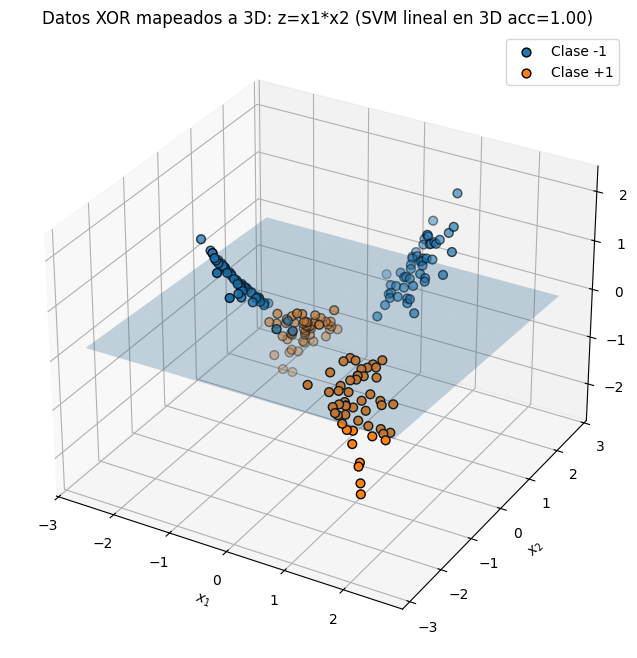

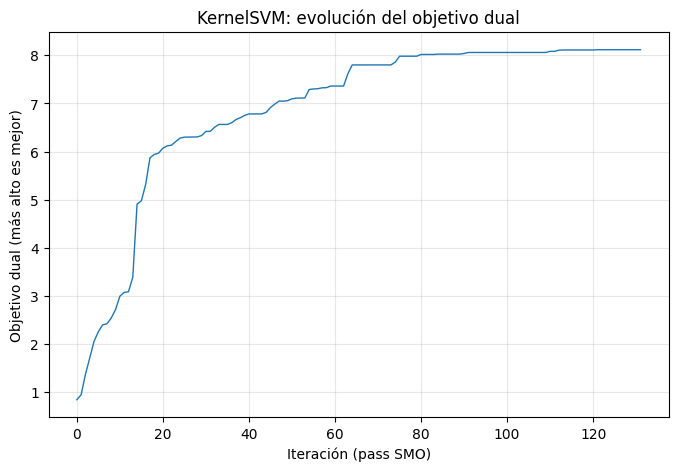

In [13]:
# Mostrar "separable en 3D"
#     Feature map explícito: (x1, x2, z) con z = x1*x2
#     En ese 3D, un hiperplano puede separar XOR.
Z = (X[:, 0] * X[:, 1]).reshape(-1, 1)
X3 = np.hstack([X, Z])  # (x1, x2, x1*x2)

# Entrenar un SVM lineal *en el espacio 3D* (con tu clase lineal)
lin3 = SVM(learning_rate=0.001, lambda_param=0.01, n_iters=2000)
lin3.fit(X3, y)
acc_lin3 = lin3.score(X3, y)

print("\n=== Resultados con mapeo a 3D (x1, x2, x1*x2) ===")
print(f"Accuracy SVM lineal en 3D:   {acc_lin3:.4f}")
print(f"w3 = {lin3.w}")
print(f"b3 = {lin3.b:.4f}")

# Gráfica 3D: puntos + plano w·[x1,x2,z] - b = 0
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X3[y == -1, 0], X3[y == -1, 1], X3[y == -1, 2],
    s=40, edgecolors="black", label="Clase -1"
)
ax.scatter(
    X3[y == 1, 0], X3[y == 1, 1], X3[y == 1, 2],
    s=40, edgecolors="black", label="Clase +1"
)

# Crear malla para el plano: w0*x + w1*y + w2*z - b = 0  => z = (b - w0*x - w1*y)/w2
w0, w1, w2 = lin3.w
b3 = lin3.b

# Evitar división por cero (muy raro, pero por robustez)
if abs(w2) > 1e-9:
    x_grid = np.linspace(X3[:, 0].min() - 1, X3[:, 0].max() + 1, 25)
    y_grid = np.linspace(X3[:, 1].min() - 1, X3[:, 1].max() + 1, 25)
    XX, YY = np.meshgrid(x_grid, y_grid)
    ZZ = (b3 - w0 * XX - w1 * YY) / w2
    ax.plot_surface(XX, YY, ZZ, alpha=0.25)
else:
    print("Nota: w2≈0, no se puede graficar el plano como z(x,y).")

ax.set_title(f"Datos XOR mapeados a 3D: z=x1*x2 (SVM lineal en 3D acc={acc_lin3:.2f})")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$z=x_1x_2$")
ax.legend()
plt.show()

# (Opcional) ver evolución del objetivo dual del kernel
plt.figure(figsize=(8, 5))
plt.plot(k.losses, linewidth=1)
plt.xlabel("Iteración (pass SMO)")
plt.ylabel("Objetivo dual (más alto es mejor)")
plt.title("KernelSVM: evolución del objetivo dual")
plt.grid(True, alpha=0.3)
plt.show()